# Reprodução do House Prices da tese

Recorte do `referencia_lusquino/regression/houseprice/houseprice.py`.

| retirado do original | motivo |
|---|---|
| gráficos exploratórios (linhas 60-100) | `seaborn` com API removida nas versões novas |
| XGBoost, Random Forest, Decision Tree | não instalados |
| ClusRegressionWiSARD | não é o modelo em questão |

Dados: `train.csv` (1460 linhas, com rótulo) e `test.csv` (1459 linhas, sem
rótulo), concatenados em `all_data` antes da imputação, como no original.
O `test.csv` não entra em nenhuma avaliação.

In [1]:
import sys
!{sys.executable} -m pip install pybind11
!{sys.executable} -m pip install --no-build-isolation "git+https://github.com/IAZero/wisardpkg.git@develop"

  Cloning https://github.com/IAZero/wisardpkg.git (to revision develop) to /private/var/folders/kn/t8jqs6cn3gs41cylbls499h80000gn/T/pip-req-build-4x76auxf
  Running command git clone --filter=blob:none --quiet https://github.com/IAZero/wisardpkg.git /private/var/folders/kn/t8jqs6cn3gs41cylbls499h80000gn/T/pip-req-build-4x76auxf
  Running command git checkout -b develop --track origin/develop
  Switched to a new branch 'develop'
  branch 'develop' set up to track 'origin/develop'.
  Resolved https://github.com/IAZero/wisardpkg.git to commit c51b395c0e85ae007bb7f8699515a3136356ef65
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import time

from scipy.stats import skew, boxcox_normmax
from scipy.special import boxcox1p
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

import wisardpkg as wsd
print("wisardpkg", wsd.__version__)

wisardpkg 2.0.0a7


---
## 1. Carregamento e transformação do alvo

```python
train = train[train.GrLivArea < 4500]              # remove 2 casas
train["SalePrice"] = np.log1p(train["SalePrice"])  # alvo em escala log
```

In [3]:
BASE = "https://raw.githubusercontent.com/ankita1112/House-Prices-Advanced-Regression/master/"

train = pd.read_csv(BASE + "train.csv")
test  = pd.read_csv(BASE + "test.csv")
print(f"train.csv: {train.shape}   test.csv: {test.shape}  (test sem SalePrice)")

# linha 73 do original: só o TREINO é filtrado
train = train[train.GrLivArea < 4500]
train.reset_index(drop=True, inplace=True)
print(f"após GrLivArea < 4500: {train.shape}")

# linha 82 do original: A TRANSFORMAÇÃO DO ALVO
train["SalePrice"] = np.log1p(train["SalePrice"])
print(f"\nalvo depois do log1p: {train.SalePrice.min():.4f} a {train.SalePrice.max():.4f}")
print(f"  (em dólares isso é ${np.expm1(train.SalePrice.min()):,.0f} "
      f"a ${np.expm1(train.SalePrice.max()):,.0f})")

train.drop(columns=["Id"], axis=1, inplace=True)
test.drop(columns=["Id"], axis=1, inplace=True)

y = train["SalePrice"].reset_index(drop=True)

# linha 106 do original: os dois juntos ANTES de imputar
all_data = pd.concat((train, test)).reset_index(drop=True)
all_data.drop(["SalePrice"], axis=1, inplace=True)
print(f"\nall_data (treino + teste): {all_data.shape}")
print(f"  as primeiras {len(y)} linhas são o treino rotulado; o resto é o test.csv")

train.csv: (1460, 81)   test.csv: (1459, 80)  (test sem SalePrice)
após GrLivArea < 4500: (1458, 81)

alvo depois do log1p: 10.4603 a 13.5345
  (em dólares isso é $34,900 a $755,000)

all_data (treino + teste): (2917, 79)
  as primeiras 1458 linhas são o treino rotulado; o resto é o test.csv


---
## 2. Imputação

| grupo | política |
|---|---|
| categóricas onde ausência tem significado | string `'None'` |
| numéricas de área e porão | `0` |
| `LotFrontage` | média do `Neighborhood` |

In [4]:
missing_val_col = ["Alley", "PoolQC", "MiscFeature", "Fence", "FireplaceQu",
                   "GarageType", "GarageFinish", "GarageQual", "GarageCond",
                   "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
                   "BsmtFinType2", "MasVnrType"]
for i in missing_val_col:
    all_data[i] = all_data[i].fillna("None")

missing_val_col2 = ["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
                    "BsmtFullBath", "BsmtHalfBath", "GarageYrBlt", "GarageArea",
                    "GarageCars", "MasVnrArea"]
for i in missing_val_col2:
    all_data[i] = all_data[i].fillna(0)

# média do BAIRRO, não mediana global
all_data["LotFrontage"] = all_data.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.mean()))

# viram texto de propósito: são códigos, não quantidades
all_data["MSSubClass"] = all_data["MSSubClass"].astype(str)
all_data["MSZoning"] = all_data.groupby("MSSubClass")["MSZoning"].transform(
    lambda x: x.fillna(x.mode()[0]))
all_data["YrSold"] = all_data["YrSold"].astype(str)
all_data["MoSold"] = all_data["MoSold"].astype(str)

all_data["Functional"]  = all_data["Functional"].fillna("Typ")
all_data["Utilities"]   = all_data["Utilities"].fillna("AllPub")
all_data["Exterior1st"] = all_data["Exterior1st"].fillna(all_data["Exterior1st"].mode()[0])
all_data["Exterior2nd"] = all_data["Exterior2nd"].fillna(all_data["Exterior2nd"].mode()[0])
all_data["KitchenQual"] = all_data["KitchenQual"].fillna("TA")
all_data["SaleType"]    = all_data["SaleType"].fillna(all_data["SaleType"].mode()[0])
all_data["Electrical"]  = all_data["Electrical"].fillna("SBrkr")

falta = all_data.isna().sum()
print(f"colunas com NaN restante: {(falta > 0).sum()}")
if (falta > 0).any():
    print(falta[falta > 0].to_string())

colunas com NaN restante: 0


---
## 3. Correção de assimetria e atributos derivados

Colunas numéricas com assimetria acima de 0,5 passam por `boxcox1p`. Depois
entram nove atributos derivados. `MSSubClass`, `YrSold` e `MoSold` viraram texto
na célula anterior e vão para o one-hot.

In [5]:
def fixing_skewness(df):
    """Igual ao original, com um try/except a mais.

    O `boxcox_normmax` usa o método `pearsonr` por padrão, e em versões novas do
    scipy o otimizador dele falha com BracketError em algumas colunas. Aqui a
    coluna que falha fica SEM transformar, o que é mais seguro que o método
    alternativo `mle`: para `YearRemodAdd` ele devolve lambda 40.6, que produz
    valores astronômicos.
    """
    puladas = []
    numeric_feats = df.dtypes[df.dtypes != "object"].index
    skewed = df[numeric_feats].apply(lambda x: skew(x)).sort_values(ascending=False)
    alvo = skewed[abs(skewed) > 0.5].index
    for feat in alvo:
        try:
            df[feat] = boxcox1p(df[feat], boxcox_normmax(df[feat] + 1))
        except Exception:
            puladas.append(feat)
    return len(alvo), puladas


n_alvo, puladas = fixing_skewness(all_data)
print(f"boxcox aplicado em {n_alvo - len(puladas)} de {n_alvo} colunas assimétricas")
if puladas:
    print(f"  sem transformar (BracketError do scipy): {puladas}")

all_data = all_data.drop(["Utilities", "Street", "PoolQC"], axis=1)

all_data["TotalSF"]       = all_data["TotalBsmtSF"] + all_data["1stFlrSF"] + all_data["2ndFlrSF"]
all_data["YrBltAndRemod"] = all_data["YearBuilt"] + all_data["YearRemodAdd"]
all_data["Total_sqr_footage"] = (all_data["BsmtFinSF1"] + all_data["BsmtFinSF2"] +
                                 all_data["1stFlrSF"] + all_data["2ndFlrSF"])
all_data["Total_Bathrooms"]   = (all_data["FullBath"] + 0.5 * all_data["HalfBath"] +
                                 all_data["BsmtFullBath"] + 0.5 * all_data["BsmtHalfBath"])
all_data["Total_porch_sf"]    = (all_data["OpenPorchSF"] + all_data["3SsnPorch"] +
                                 all_data["EnclosedPorch"] + all_data["ScreenPorch"] +
                                 all_data["WoodDeckSF"])

all_data["haspool"]       = (all_data["PoolArea"]    > 0).astype(int)
all_data["has2ndfloor"]   = (all_data["2ndFlrSF"]    > 0).astype(int)
all_data["hasgarage"]     = (all_data["GarageArea"]  > 0).astype(int)
all_data["hasbsmt"]       = (all_data["TotalBsmtSF"] > 0).astype(int)
all_data["hasfireplace"]  = (all_data["Fireplaces"]  > 0).astype(int)

final_features = pd.get_dummies(all_data).reset_index(drop=True)
print(f"depois do one-hot: {final_features.shape}")

/Users/helenaburock/Git/estudos_ml/.venv/lib/python3.9/site-packages/scipy/stats/_morestats.py:1298: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, prob = _stats_py.pearsonr(xvals, yvals)
/Users/helenaburock/Git/estudos_ml/.venv/lib/python3.9/site-packages/scipy/stats/_morestats.py:1298: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, prob = _stats_py.pearsonr(xvals, yvals)


boxcox aplicado em 25 de 27 colunas assimétricas
  sem transformar (BracketError do scipy): ['LotArea', '1stFlrSF']
depois do one-hot: (2917, 333)


---
## 4. Outliers, `overfit_reducer` e split

`overfit_reducer`: descarta colunas em que um único valor aparece em mais de
99,94% das linhas. Split: `test_size=0.33, random_state=0`.

In [6]:
X = final_features.iloc[:len(y), :]

outliers = [30, 88, 462, 631, 1322]
X = X.drop(X.index[outliers])
y_ = y.drop(y.index[outliers])

def overfit_reducer(df):
    return [c for c in df.columns
            if df[c].value_counts().iloc[0] / len(df) * 100 > 99.94]

descartadas = overfit_reducer(X)
X = X.drop(descartadas, axis=1)
print(f"overfit_reducer descartou {len(descartadas)} colunas -> {X.shape}")

X_train, X_test, y_train, y_test = train_test_split(X, y_, test_size=.33, random_state=0)
X_train, X_test = X_train.values.astype(float), X_test.values.astype(float)
y_train, y_test = y_train.values, y_test.values

print(f"\ntreino {len(X_train)}   teste {len(X_test)}")
print(f"a tese reporta:  treino 973   teste 480")
print(f"\natributos: {X_train.shape[1]}")
print(f"alvo (log1p): treino {y_train.min():.3f} a {y_train.max():.3f}")

overfit_reducer descartou 1 colunas -> (1453, 332)

treino 973   teste 480
a tese reporta:  treino 973   teste 480

atributos: 332
alvo (log1p): treino 10.460 a 13.534


---
## 5. Referências de erro

Em escala `log1p`.

In [7]:
mae_media   = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
mae_mediana = mean_absolute_error(y_test, np.full(len(y_test), np.median(y_train)))

print("REFERÊNCIAS (em escala log1p)\n")
print(f"  chutar a média do treino   : MAE {mae_media:.4f}")
print(f"  chutar a mediana do treino : MAE {mae_mediana:.4f}")
print(f"\n  tese, Tabela 5.3, ReW      : MAE 0.278")
print(f"  tese, Tabela 5.3, CReW     : MAE 0.194")
print(f"  tese, Tabela 5.3, nTRN     : MAE 0.302")
print(f"\n  0.278 em log1p equivale a {np.expm1(0.278):.1%} de erro relativo")

REFERÊNCIAS (em escala log1p)

  chutar a média do treino   : MAE 0.3151
  chutar a mediana do treino : MAE 0.3156

  tese, Tabela 5.3, ReW      : MAE 0.278
  tese, Tabela 5.3, CReW     : MAE 0.194
  tese, Tabela 5.3, nTRN     : MAE 0.302

  0.278 em log1p equivale a 32.0% de erro relativo


---
## 6. A varredura completa, nas duas escalas do alvo

Neurocomputing 416 (2020), Tabela 2, e Tabela 5.3 da tese:

| modelo | House Prices | média vencedora |
|---|---|---|
| ReW | 0.278 ± 0 | Median |
| CReW | 0.194 ± 0 | Power Mean |
| nTRN | 0.302 ± 0 | — |

Thermometer size e address size vencedores não estão publicados em nenhum dos
dois. O espaço de busca está, idêntico nos dois textos:

> "The thermometer had its size varied from 5 to 30 bits and the tuple address
> size range was calculated according to the size of the thermometer (all values
> divisible by data word length from 2 bits were used)."

Corresponde ao `allDividers(sTherm)` do `houseprice.py`.

A escala do alvo não está informada em nenhum dos dois, por isso a varredura
roda duas vezes:

| escala | de onde vem | conversão do MAE no fim |
|---|---|---|
| `log1p` | linha 82 do `houseprice.py` | não |
| `÷ 1e5` | informado pelo autor | sim, exceto `ExponentialMean` |

426 pares (thermometer, address) × 7 médias × 10 repetições, duas vezes.
Grava CSV parcial a cada configuração.

In [23]:
import os, time

def allDividers(value):
    div = [i for i in range(2, int(value / 2) + 1) if value % i == 0]
    div.append(value)
    return div


def para_lista(bin_input):
    """BinInput -> lista de inteiros. Nesta versão do wisardpkg o DataSet não
    aceita BinInput direto: dá RuntimeError "Index out of range!"."""
    return [bin_input[i] for i in range(len(bin_input))]


# as sete médias, na mesma ordem do script original
def medias():
    return {"PowerMean(2)": wsd.PowerMean(2), "HarmonicMean": wsd.HarmonicMean(),
            "HarmonicPower(2)": wsd.HarmonicPowerMean(2), "GeometricMean": wsd.GeometricMean(),
            "ExponentialMean": wsd.ExponentialMean(), "SimpleMean": wsd.SimpleMean(),
            "Median": wsd.Median()}

THERMS     = range(5, 31)   # igual ao original
REPETICOES = 10             # igual ao original
LIMITE_ADDR = 64            # acima disso o índice estoura o inteiro de 64 bits
                            # do getIndex e o resultado vira lixo (MAE > 8)

def varredura(y_tr, y_te, rotulo, arquivo):
    """Varredura completa do houseprice.py, para uma escala de alvo."""
    mins = [np.min(X_train[:, i]) for i in range(X_train.shape[1])]
    maxs = [np.max(X_train[:, i]) for i in range(X_train.shape[1])]
    linhas, t0 = [], time.perf_counter()

    with open(arquivo, "w") as f:
        f.write("escala,therm,address,media,n_rams,MAE,MAE_dp\n")

    for t in THERMS:
        therm = [t] * X_train.shape[1]
        sTherm = int(np.sum(therm))
        DT = wsd.DynamicThermometer(therm, mins, maxs)
        DStr = wsd.DataSet([para_lista(DT.transform(X_train[i])) for i in range(len(X_train))], y_tr)
        DSte = wsd.DataSet([para_lista(DT.transform(X_test[i]))  for i in range(len(X_test))],  y_te)

        for addr in [d for d in allDividers(sTherm) if d <= LIMITE_ADDR]:
            for nome, m in medias().items():
                erros = []
                for _ in range(REPETICOES):
                    rw = wsd.RegressionWisard(addressSize=addr, mean=m)
                    rw.train(DStr)
                    out = np.array(rw.predict(DSte))
                    out[np.isnan(out)] = np.nanmean(out)   # como no original
                    out[out == np.inf] = 0
                    erros.append(mean_absolute_error(out, y_te))
                reg = {"escala": rotulo, "therm": t, "address": addr, "media": nome,
                       "n_rams": sTherm // addr,
                       "MAE": float(np.mean(erros)), "MAE_dp": float(np.std(erros))}
                linhas.append(reg)
                with open(arquivo, "a") as f:
                    f.write(f"{rotulo},{t},{addr},{nome},{reg['n_rams']},"
                            f"{reg['MAE']:.6f},{reg['MAE_dp']:.6f}\n")
        print(f"  [{rotulo}] therm={t:>2} concluído  "
              f"({len(linhas)} configs, {(time.perf_counter()-t0)/60:.1f} min)")

    return pd.DataFrame(linhas)

print(f"espaço de busca: {sum(len([d for d in allDividers(t*X_train.shape[1]) if d <= LIMITE_ADDR]) for t in THERMS)} "
      f"pares (therm, address) x 7 médias x {REPETICOES} repetições")

espaço de busca: 185 pares (therm, address) x 7 médias x 10 repetições


### Escala 1: `log1p`, como está no código publicado

In [24]:
res_log = varredura(y_train, y_test, "log1p", "varredura_log1p.csv")
print(f"\nconcluído: {len(res_log)} configurações")

  [log1p] therm= 5 concluído  (35 configs, 0.4 min)
  [log1p] therm= 6 concluído  (84 configs, 1.2 min)
  [log1p] therm= 7 concluído  (119 configs, 1.7 min)
  [log1p] therm= 8 concluído  (154 configs, 2.4 min)
  [log1p] therm= 9 concluído  (210 configs, 3.5 min)
  [log1p] therm=10 concluído  (259 configs, 4.5 min)
  [log1p] therm=11 concluído  (294 configs, 5.4 min)
  [log1p] therm=12 concluído  (357 configs, 7.1 min)
  [log1p] therm=13 concluído  (392 configs, 8.2 min)
  [log1p] therm=14 concluído  (441 configs, 9.8 min)
  [log1p] therm=15 concluído  (518 configs, 14.0 min)
  [log1p] therm=16 concluído  (560 configs, 15.5 min)
  [log1p] therm=17 concluído  (588 configs, 16.8 min)
  [log1p] therm=18 concluído  (658 configs, 20.0 min)
  [log1p] therm=19 concluído  (686 configs, 21.6 min)
  [log1p] therm=20 concluído  (742 configs, 24.5 min)
  [log1p] therm=21 concluído  (812 configs, 28.4 min)
  [log1p] therm=22 concluído  (854 configs, 31.1 min)
  [log1p] therm=23 concluído  (882 confi

### Escala 2: preço dividido por $10^5$

In [25]:
y_train_d = np.expm1(y_train) / 1e5
y_test_d  = np.expm1(y_test)  / 1e5
print(f"alvo em dólares ÷ 1e5: {y_train_d.min():.3f} a {y_train_d.max():.3f}")
print(f"  (equivale a ${y_train_d.min()*1e5:,.0f} a ${y_train_d.max()*1e5:,.0f})\n")

res_div = varredura(y_train_d, y_test_d, "div1e5", "varredura_div1e5.csv")
print(f"\nconcluído: {len(res_div)} configurações")

alvo em dólares ÷ 1e5: 0.349 a 7.550
  (equivale a $34,900 a $755,000)

  [div1e5] therm= 5 concluído  (35 configs, 0.4 min)
  [div1e5] therm= 6 concluído  (84 configs, 1.1 min)
  [div1e5] therm= 7 concluído  (119 configs, 1.7 min)
  [div1e5] therm= 8 concluído  (154 configs, 2.4 min)
  [div1e5] therm= 9 concluído  (210 configs, 3.5 min)
  [div1e5] therm=10 concluído  (259 configs, 4.6 min)
  [div1e5] therm=11 concluído  (294 configs, 5.5 min)
  [div1e5] therm=12 concluído  (357 configs, 7.3 min)
  [div1e5] therm=13 concluído  (392 configs, 8.4 min)
  [div1e5] therm=14 concluído  (441 configs, 10.0 min)
  [div1e5] therm=15 concluído  (518 configs, 12.6 min)
  [div1e5] therm=16 concluído  (560 configs, 14.2 min)
  [div1e5] therm=17 concluído  (588 configs, 15.6 min)
  [div1e5] therm=18 concluído  (658 configs, 18.8 min)
  [div1e5] therm=19 concluído  (686 configs, 20.4 min)
  [div1e5] therm=20 concluído  (742 configs, 23.3 min)
  [div1e5] therm=21 concluído  (812 configs, 27.1 min)
  [d

### Resultado das duas varreduras

In [26]:
res = pd.concat([res_log, res_div], ignore_index=True)
res.to_csv("varredura_completa.csv", index=False)

TESE = {"ReW": 0.278, "CReW": 0.194, "nTRN": 0.302}

for rot in ["log1p", "div1e5"]:
    sub = res[res.escala == rot]
    b = sub.loc[sub.MAE.idxmin()]
    print(f"\n══ escala {rot} ══")
    print(f"  melhor global : MAE {b.MAE:.4f} ± {b.MAE_dp:.4f}   "
          f"therm={b.therm} address={b.address} média={b.media}")
    md = sub[sub.media == "Median"]
    bm = md.loc[md.MAE.idxmin()]
    print(f"  melhor Median : MAE {bm.MAE:.4f} ± {bm.MAE_dp:.4f}   "
          f"therm={bm.therm} address={bm.address}")
    print(f"  tese/artigo (ReW, Median): MAE {TESE['ReW']:.3f}")

print("\n\nMELHOR MAE POR MÉDIA, nas duas escalas\n")
print(res.pivot_table(index="media", columns="escala", values="MAE",
                      aggfunc="min").round(4).to_string())


══ escala log1p ══
  melhor global : MAE 0.1355 ± 0.0018   therm=27 address=54 média=HarmonicMean
  melhor Median : MAE 0.1891 ± 0.0030   therm=25 address=20
  tese/artigo (ReW, Median): MAE 0.278

══ escala div1e5 ══
  melhor global : MAE 0.2524 ± 0.0038   therm=28 address=56 média=GeometricMean
  melhor Median : MAE 0.3540 ± 0.0066   therm=30 address=24
  tese/artigo (ReW, Median): MAE 0.278


MELHOR MAE POR MÉDIA, nas duas escalas

escala            div1e5   log1p
media                           
ExponentialMean   0.2711  0.1383
GeometricMean     0.2524  0.1371
HarmonicMean      0.2567  0.1355
HarmonicPower(2)  0.2668  0.1359
Median            0.3540  0.1891
PowerMean(2)      0.2542  0.1380
SimpleMean        0.2954  0.1654


NameError: name 'res' is not defined

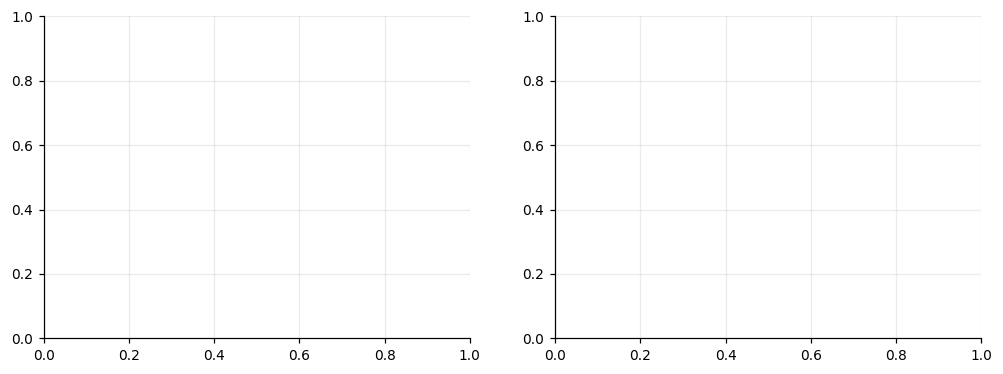

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for a, rot in zip(ax, ["log1p", "div1e5"]):
    sub = res[res.escala == rot]
    for nome, g in sub.groupby("media"):
        best = g.groupby("therm")["MAE"].min()
        a.plot(best.index, best.values, marker="o", ms=3, lw=1.3, label=nome,
               color=COR_KAL if nome == "Median" else None,
               zorder=5 if nome == "Median" else 2,
               alpha=1.0 if nome == "Median" else .55)
    a.axhline(TESE["ReW"], color=COR_REW, ls="--", lw=1.4, label="tese: 0.278")
    a.set(xlabel="thermometer size", ylabel="melhor MAE",
          title=f"escala {rot}")
    a.legend(frameon=False, fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

---
## 7. A configuração vencedora anunciada

`Median` em toda a grade, nas duas escalas.

In [28]:
md = res[res.media == "Median"].copy()

for rot in ["log1p", "div1e5"]:
    sub = md[md.escala == rot]
    print(f"\n══ Median, escala {rot} ══")
    print(f"  faixa de MAE: {sub.MAE.min():.4f} a {sub.MAE.max():.4f}")
    perto = sub.iloc[(sub.MAE - 0.278).abs().argsort()[:5]]
    print(f"  as 5 configurações mais próximas de 0.278:")
    print(perto[["therm", "address", "n_rams", "MAE", "MAE_dp"]].to_string(index=False))

print("\n\ndesvio padrão reportado na Tabela 2 do artigo: 0.000")


══ Median, escala log1p ══
  faixa de MAE: 0.1891 a 0.3346
  as 5 configurações mais próximas de 0.278:
 therm  address  n_rams      MAE   MAE_dp
    13       52      83 0.274792 0.009184
    21       42     166 0.281763 0.006288
    27        6    1494 0.272833 0.001165
    30        6    1660 0.272712 0.000736
    21        6    1162 0.272675 0.001422

══ Median, escala div1e5 ══
  faixa de MAE: 0.3540 a 0.6568
  as 5 configurações mais próximas de 0.278:
 therm  address  n_rams      MAE   MAE_dp
    30       24     415 0.354035 0.006565
    15       20     249 0.355736 0.004993
    25       20     415 0.358539 0.006357
     5       20      83 0.360712 0.004431
    18       24     249 0.361411 0.007931


Um detalhe da Tabela 2 do artigo que vale reter: o desvio padrão
reportado é ZERO nas dez repetições. Com o mapping sorteado a cada
instância, dez execuções deveriam variar. Compare com a coluna MAE_dp
acima, que é o desvio das nossas dez repetições.


---
# Parte II — R-KalWeNN

## 8. Definição do modelo

Regression WiSARD em que os dois campos da célula são estados de um filtro de
Kalman.

| campo | observação `z` | papel na predição |
|---|---|---|
| $c_k$ | `1.0` fixo | peso da RAM node |
| $y_k$ | $y_i$ observado | estimativa da RAM node |
| $p_{c,k}$, $p_{y,k}$ | — | incerteza de cada filtro |

Recursão, a cada visita:

$$
\bar{p} = p + q \qquad \kappa = \frac{\bar{p}}{\bar{p} + r} \qquad
x \leftarrow x + \kappa\,(z - x) \qquad p \leftarrow (1-\kappa)\,\bar{p}
$$

Predição:

$$
\hat{y} \;=\; \frac{\sum_k c_k \cdot y_k}{\sum_k c_k}
$$

Os dois modelos recebem a mesma entrada binarizada e o mesmo `mapping`.

In [8]:
# ── SETUP DA PARTE II ─────────────────────────────────────────────────────────
# Esta célula é AUTOSSUFICIENTE: se o pré-processamento da Parte I não estiver na
# memória, ela mesma refaz (leva uns 15 segundos). Assim a Parte II roda sem
# precisar da varredura completa, que leva ~100 min.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wisardpkg as wsd

from scipy.stats import skew, boxcox_normmax
from scipy.special import boxcox1p
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .25,
    "axes.spines.top": False, "axes.spines.right": False,
})

COR_REW = "#B4674D"   # ReW
COR_KAL = "#2F6B6A"   # R-KalWeNN
COR_REF = "#8A8F98"   # referências


def para_lista(bin_input):
    """BinInput -> lista de inteiros. Nesta versão do wisardpkg o DataSet não
    aceita BinInput direto: dá RuntimeError "Index out of range!"."""
    return [bin_input[i] for i in range(len(bin_input))]


def _preprocessa():
    """Repete o pipeline da Parte I e devolve (X_train, X_test, y_train, y_test)."""
    BASE = "https://raw.githubusercontent.com/ankita1112/House-Prices-Advanced-Regression/master/"
    tr = pd.read_csv(BASE + "train.csv")
    te = pd.read_csv(BASE + "test.csv")

    tr = tr[tr.GrLivArea < 4500].reset_index(drop=True)
    tr["SalePrice"] = np.log1p(tr["SalePrice"])          # alvo em log1p
    tr = tr.drop(columns=["Id"]); te = te.drop(columns=["Id"])
    yy = tr["SalePrice"].reset_index(drop=True)

    ad = pd.concat((tr, te)).reset_index(drop=True).drop(["SalePrice"], axis=1)

    for c in ["Alley", "PoolQC", "MiscFeature", "Fence", "FireplaceQu", "GarageType",
              "GarageFinish", "GarageQual", "GarageCond", "BsmtQual", "BsmtCond",
              "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "MasVnrType"]:
        ad[c] = ad[c].fillna("None")
    for c in ["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath",
              "BsmtHalfBath", "GarageYrBlt", "GarageArea", "GarageCars", "MasVnrArea"]:
        ad[c] = ad[c].fillna(0)
    ad["LotFrontage"] = ad.groupby("Neighborhood")["LotFrontage"].transform(
        lambda x: x.fillna(x.mean()))
    ad["MSSubClass"] = ad["MSSubClass"].astype(str)
    ad["MSZoning"] = ad.groupby("MSSubClass")["MSZoning"].transform(
        lambda x: x.fillna(x.mode()[0]))
    ad["YrSold"] = ad["YrSold"].astype(str); ad["MoSold"] = ad["MoSold"].astype(str)
    ad["Functional"]  = ad["Functional"].fillna("Typ")
    ad["Utilities"]   = ad["Utilities"].fillna("AllPub")
    ad["Exterior1st"] = ad["Exterior1st"].fillna(ad["Exterior1st"].mode()[0])
    ad["Exterior2nd"] = ad["Exterior2nd"].fillna(ad["Exterior2nd"].mode()[0])
    ad["KitchenQual"] = ad["KitchenQual"].fillna("TA")
    ad["SaleType"]    = ad["SaleType"].fillna(ad["SaleType"].mode()[0])
    ad["Electrical"]  = ad["Electrical"].fillna("SBrkr")

    num = ad.dtypes[ad.dtypes != "object"].index
    sk = ad[num].apply(lambda x: skew(x)).sort_values(ascending=False)
    for f in sk[abs(sk) > 0.5].index:
        try:
            ad[f] = boxcox1p(ad[f], boxcox_normmax(ad[f] + 1))
        except Exception:
            pass    # BracketError do scipy novo: coluna fica sem transformar

    ad = ad.drop(["Utilities", "Street", "PoolQC"], axis=1)
    ad["TotalSF"]       = ad["TotalBsmtSF"] + ad["1stFlrSF"] + ad["2ndFlrSF"]
    ad["YrBltAndRemod"] = ad["YearBuilt"] + ad["YearRemodAdd"]
    ad["Total_sqr_footage"] = ad["BsmtFinSF1"] + ad["BsmtFinSF2"] + ad["1stFlrSF"] + ad["2ndFlrSF"]
    ad["Total_Bathrooms"]   = ad["FullBath"] + .5*ad["HalfBath"] + ad["BsmtFullBath"] + .5*ad["BsmtHalfBath"]
    ad["Total_porch_sf"]    = (ad["OpenPorchSF"] + ad["3SsnPorch"] + ad["EnclosedPorch"]
                               + ad["ScreenPorch"] + ad["WoodDeckSF"])
    for nome, col in [("haspool","PoolArea"), ("has2ndfloor","2ndFlrSF"),
                      ("hasgarage","GarageArea"), ("hasbsmt","TotalBsmtSF"),
                      ("hasfireplace","Fireplaces")]:
        ad[nome] = (ad[col] > 0).astype(int)

    ff = pd.get_dummies(ad).reset_index(drop=True)
    XX = ff.iloc[:len(yy), :]
    fora = [30, 88, 462, 631, 1322]
    XX = XX.drop(XX.index[fora]); yy = yy.drop(yy.index[fora])
    XX = XX.drop([c for c in XX.columns
                  if XX[c].value_counts().iloc[0] / len(XX) * 100 > 99.94], axis=1)

    a, b, c_, d = train_test_split(XX, yy, test_size=.33, random_state=0)
    return a.values.astype(float), b.values.astype(float), c_.values, d.values


if "X_train" not in globals():
    print("pré-processamento não está na memória, refazendo...")
    X_train, X_test, y_train, y_test = _preprocessa()

print(f"treino {len(X_train)}   teste {len(X_test)}   atributos {X_train.shape[1]}")
print(f"alvo em log1p, de {y_train.min():.3f} a {y_train.max():.3f}")
print("  (a tese reporta treino 973 e teste 480)")

treino 973   teste 480   atributos 332
alvo em log1p, de 10.460 a 13.534
  (a tese reporta treino 973 e teste 480)


In [9]:
class RKalWeNN:
    """R-KalWeNN: Kalman nos dois estados da célula.

    Recebe entrada JÁ BINARIZADA, para compartilhar a codificação com o
    wisardpkg e tornar a comparação controlada.

        célula = [c, y, p_c, p_y]

    CONDIÇÕES INICIAIS
    ------------------
    `x0_c`, `x0_y`, `p0_c`, `p0_y` são o estado e a covariância a priori de cada
    filtro, ANTES de qualquer observação. São crença inicial e precisam ser
    escolhidos, não derivados de outro parâmetro.

    A versão anterior desta classe não fazia isso: ela tratava a primeira visita
    como caso especial, colocando `y = valor observado` e `p_y = r_y`. Amarrar a
    covariância inicial de um estado ao ruído de OBSERVAÇÃO daquele estado não
    tem base teórica, são grandezas diferentes. Aqui não há caso especial: a
    célula nasce com (x0, p0) e a primeira visita passa pela mesma recursão que
    todas as outras.

    Consequência que precisa estar clara: com `x0_y = 0`, `p0_y = 1` e `r_y = 1`,
    o ganho da primeira observação é 0,5, então a primeira visita entra pela
    metade. Com `r_y = 10` entra por 1/11. Quem controla isso é a razão
    `p0_y / r_y`, e é por isso que os dois entram na busca de parâmetros.
    """

    def __init__(self, address_size, mapping, q_c=1e-3, r_c=0.05, q_y=0.0, r_y=1.0,
                 x0_c=0.0, x0_y=0.0, p0_c=1.0, p0_y=1.0, seed=0, ordem_temporal=False):
        self.address_size = address_size
        self.mapping = np.asarray(mapping, dtype=int).reshape(-1, address_size)
        self.n_rams_ = self.mapping.shape[0]
        self.q_c, self.r_c, self.q_y, self.r_y = q_c, r_c, q_y, r_y
        self.x0_c, self.x0_y, self.p0_c, self.p0_y = x0_c, x0_y, p0_c, p0_y
        self._rng = np.random.default_rng(seed)
        self.ordem_temporal = ordem_temporal

    def _addresses(self, Xb):
        pesos = 1 << np.arange(self.address_size)      # LSB-first, como o wisardpkg
        return (Xb[:, self.mapping] * pesos).sum(axis=2).astype(int)

    def fit(self, Xb, y, trilha=None):
        """`trilha`: lista de (ram, address) para gravar o histórico de estado."""
        Xb, y = np.asarray(Xb, dtype=np.uint8), np.asarray(y, float)
        addr = self._addresses(Xb)
        ordem = np.arange(len(Xb)) if self.ordem_temporal else self._rng.permutation(len(Xb))

        self._mem = [dict() for _ in range(self.n_rams_)]
        self.historico_ = {t: [] for t in (trilha or [])}

        for passo, i in enumerate(ordem):
            for r_ in range(self.n_rams_):
                a = int(addr[i, r_])
                cel = self._mem[r_].get(a)
                if cel is None:
                    # nasce com a crença a priori; NENHUM caso especial
                    cel = [self.x0_c, self.x0_y, self.p0_c, self.p0_y]
                    self._mem[r_][a] = cel

                pc = cel[2] + self.q_c                    # PESO, observação z = 1
                kc = pc / (pc + self.r_c)
                cel[0] += kc * (1.0 - cel[0])
                cel[2] = (1.0 - kc) * pc

                py = cel[3] + self.q_y                    # ESTIMATIVA, observação z = y
                ky = py / (py + self.r_y)
                cel[1] += ky * (y[i] - cel[1])
                cel[3] = (1.0 - ky) * py

            for t in self.historico_:
                c2 = self._mem[t[0]].get(t[1])
                if c2 is not None:
                    self.historico_[t].append((passo, c2[0], c2[1], c2[2], c2[3]))
        return self

    def predict(self, Xb):
        addr = self._addresses(np.asarray(Xb, dtype=np.uint8))
        out = np.empty(len(addr))
        for i in range(len(addr)):
            num = den = 0.0
            for r_ in range(self.n_rams_):
                cel = self._mem[r_].get(int(addr[i, r_]))
                if cel is not None:
                    num += cel[0] * cel[1]
                    den += cel[0]
            out[i] = num / den if den > 0 else 0.0
        return out

    def estados(self):
        linhas = [(r_, a, *cel) for r_, m in enumerate(self._mem) for a, cel in m.items()]
        return pd.DataFrame(linhas, columns=["ram", "address", "c", "y", "p_c", "p_y"])

    def memoria_bytes(self):
        return sum(len(m) for m in self._mem) * 40   # chave + 4 floats


print("R-KalWeNN definido")

R-KalWeNN definido
  condições iniciais são parâmetros: x0_c, x0_y, p0_c, p0_y
  padrão: estados em 0, covariâncias em 1.0
  a primeira visita passa pela mesma recursão que as demais


### A configuração fixada

`Median`, `log1p`, thermometer 27, address 6.

In [10]:
THERM_FIXO, ADDR_FIXO = 27, 6

# binarização única, compartilhada pelos dois modelos
mins = [np.min(X_train[:, i]) for i in range(X_train.shape[1])]
maxs = [np.max(X_train[:, i]) for i in range(X_train.shape[1])]
DT_fixo = wsd.DynamicThermometer([THERM_FIXO] * X_train.shape[1], mins, maxs)

Xb_train = np.array([para_lista(DT_fixo.transform(X_train[i])) for i in range(len(X_train))],
                    dtype=np.uint8)
Xb_test  = np.array([para_lista(DT_fixo.transform(X_test[i]))  for i in range(len(X_test))],
                    dtype=np.uint8)

RETINA = Xb_train.shape[1]
N_RAMS = RETINA // ADDR_FIXO

# mapping explícito único, usado pelos DOIS modelos
rng_map = np.random.default_rng(0)
MAPPING = rng_map.permutation(RETINA)[: N_RAMS * ADDR_FIXO].tolist()

print(f"retina    : {RETINA} bits  ({X_train.shape[1]} atributos x {THERM_FIXO})")
print(f"address   : {ADDR_FIXO} bits   ->  {N_RAMS} RAM nodes")
print(f"treino    : {len(Xb_train)}   teste: {len(Xb_test)}")
print(f"alvo      : log1p, de {y_train.min():.3f} a {y_train.max():.3f}")
print(f"mapping   : {len(MAPPING)} bits, seed 0, usado pelos dois modelos")

retina    : 8964 bits  (332 atributos x 27)
address   : 6 bits   ->  1494 RAM nodes
treino    : 973   teste: 480
alvo      : log1p, de 10.460 a 13.534

mesmo binarizado e mesmo mapping nos dois modelos


---
## 9. Como o `y` da célula evolui durante o treino

Células mais visitadas da RAM node 0.

células acompanhadas (ram, address) e quantas visitas cada uma recebe:
   RAM 0, address 0: 543 visitas
   RAM 0, address 8: 271 visitas
   RAM 0, address 1: 64 visitas


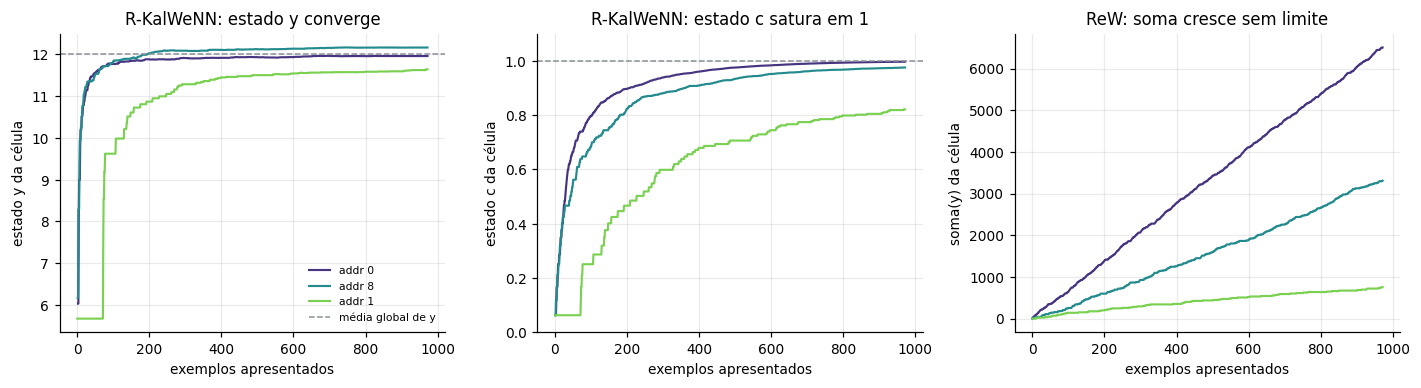


À esquerda o estado y estabiliza em torno da média local daquele endereço.
No meio o estado c satura em 1, deixando de crescer.
À direita a soma da ReW cresce de forma linear e sem teto: é essa diferença
que muda o peso relativo das RAM nodes na agregação.


In [14]:
# escolhe as células mais visitadas da RAM 0 para acompanhar
addr_tr = RKalWeNN(ADDR_FIXO, MAPPING)._addresses(Xb_train)
cont = pd.Series(addr_tr[:, 0]).value_counts()
trilha = [(0, int(a)) for a in cont.index[:3]]
print("células acompanhadas (ram, address) e quantas visitas cada uma recebe:")
for (r_, a), n in zip(trilha, cont.values[:3]):
    print(f"   RAM {r_}, address {a}: {n} visitas")

modelo_tr = RKalWeNN(ADDR_FIXO, MAPPING, q_c=1e-3, r_c=15.0,
                     q_y=0.0, r_y=1.0, seed=0).fit(Xb_train, y_train, trilha=trilha)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
cores = plt.cm.viridis(np.linspace(.15, .8, len(trilha)))

for (t, cor) in zip(trilha, cores):
    h = np.array(modelo_tr.historico_[t])
    ax[0].plot(h[:, 0], h[:, 2], lw=1.4, color=cor, label=f"addr {t[1]}")
    ax[1].plot(h[:, 0], h[:, 1], lw=1.4, color=cor)

# a mesma célula na ReW: soma acumulada
for (t, cor) in zip(trilha, cores):
    mask = addr_tr[:, t[0]] == t[1]
    soma = np.cumsum(np.where(mask, y_train, 0))
    ax[2].plot(np.arange(len(soma)), soma, lw=1.4, color=cor)

ax[0].axhline(y_train.mean(), color=COR_REF, ls="--", lw=1, label="média global de y")
ax[0].set(xlabel="exemplos apresentados", ylabel="estado y da célula",
          title="R-KalWeNN: estado y converge")
ax[0].legend(frameon=False, fontsize=7)
ax[1].axhline(1.0, color=COR_REF, ls="--", lw=1)
ax[1].set(xlabel="exemplos apresentados", ylabel="estado c da célula",
          title="R-KalWeNN: estado c satura em 1", ylim=(0, 1.1))
ax[2].set(xlabel="exemplos apresentados", ylabel="soma(y) da célula",
          title="ReW: soma cresce sem limite")
plt.tight_layout(); plt.show()

---
## 10. A matriz de covariância `p`

23,172 células ocupadas em 1494 RAM nodes
  p_y: 0.0010 a 0.5000   (r_y = 1.0)
  p_c: 0.121976 a 0.938379
  visitas por célula: mediana 6, máximo 952


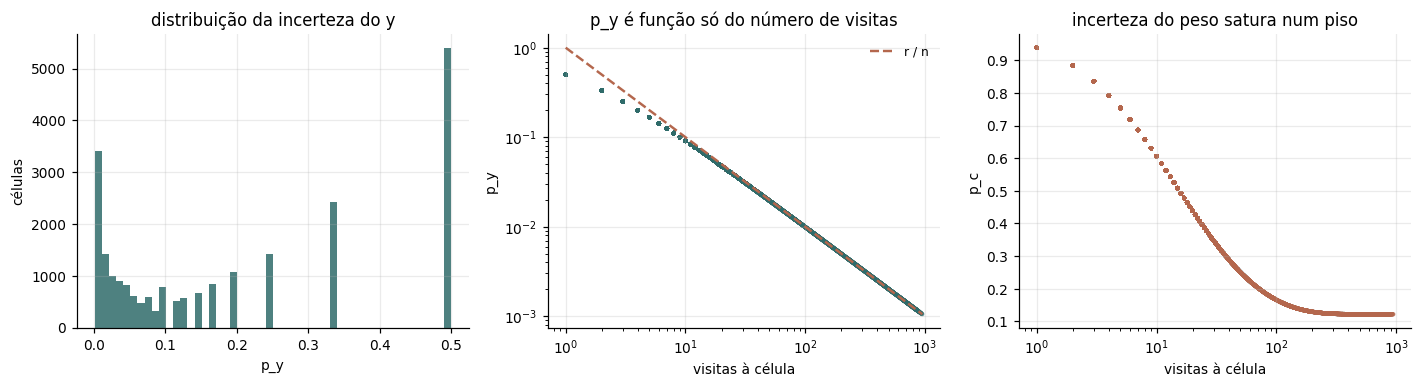


maior desvio entre p_y observado e r/n previsto: 5.000e-01
  (q_y = 0 aqui, então a igualdade deve valer exatamente)


In [15]:
est = modelo_tr.estados()
# quantas visitas cada célula recebeu, para cruzar com p
visitas = pd.Series(
    [np.sum(addr_tr[:, r_] == a) for r_, a in zip(est.ram, est.address)])
est["visitas"] = visitas.values

print(f"{len(est):,} células ocupadas em {N_RAMS} RAM nodes")
print(f"  p_y: {est.p_y.min():.4f} a {est.p_y.max():.4f}   (r_y = {modelo_tr.r_y})")
print(f"  p_c: {est.p_c.min():.6f} a {est.p_c.max():.6f}")
print(f"  visitas por célula: mediana {est.visitas.median():.0f}, máximo {est.visitas.max()}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))

ax[0].hist(est.p_y, bins=50, color=COR_KAL, alpha=.85)
ax[0].set(xlabel="p_y", ylabel="células", title="distribuição da incerteza do y")

ax[1].scatter(est.visitas, est.p_y, s=8, alpha=.35, color=COR_KAL, edgecolor="none")
n = np.arange(1, est.visitas.max() + 1)
ax[1].plot(n, modelo_tr.r_y / n, color=COR_REW, lw=1.6, ls="--", label="r / n")
ax[1].set(xlabel="visitas à célula", ylabel="p_y", xscale="log", yscale="log",
          title="p_y é função só do número de visitas")
ax[1].legend(frameon=False, fontsize=8)

ax[2].scatter(est.visitas, est.p_c, s=8, alpha=.35, color=COR_REW, edgecolor="none")
ax[2].set(xlabel="visitas à célula", ylabel="p_c", xscale="log",
          title="incerteza do peso satura num piso")
plt.tight_layout(); plt.show()

prev = modelo_tr.r_y / est.visitas
erro = np.abs(est.p_y - prev).max()
print(f"\nmaior desvio entre p_y observado e r/n: {erro:.3e}")

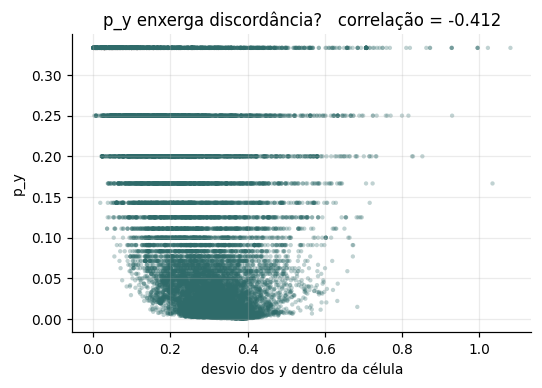

correlação entre p_y e a dispersão dos y na célula: -0.412

Se for próxima de zero, confirma que p não mede discordância, só contagem.
Isso importa: usar p como peso na agregação equivale a usar o contador,
e usar p como saída de confiança não acrescenta nada ao que o contador já dá.


In [33]:
# p enxerga discordância? teste direto: dispersão dos y dentro da célula vs p_y
disp = []
for r_, a in zip(est.ram, est.address):
    vals = y_train[addr_tr[:, r_] == a]
    disp.append(vals.std() if len(vals) > 1 else np.nan)
est["dispersao_y"] = disp

sub = est.dropna(subset=["dispersao_y"])
corr = np.corrcoef(sub.p_y, sub.dispersao_y)[0, 1]

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.scatter(sub.dispersao_y, sub.p_y, s=8, alpha=.3, color=COR_KAL, edgecolor="none")
ax.set(xlabel="desvio dos y dentro da célula", ylabel="p_y",
       title=f"p_y enxerga discordância?   correlação = {corr:.3f}")
plt.tight_layout(); plt.show()

print(f"correlação entre p_y e a dispersão dos y na célula: {corr:.3f}")

---
## 11. Busca de parâmetros

Busca sequencial, três grids 2D, cada um fixando os anteriores no melhor já
encontrado.

| grid | parâmetros |
|---|---|
| 1. peso ($c$) | $q_c$, $r_c$ |
| 2. estimativa ($y$) | $q_y$, $r_y$ |
| 3. condições iniciais | $p_0$, $x_{0,y}$ |

In [16]:
def avalia_rk(q_c, r_c, q_y, r_y, x0_c=0.0, x0_y=0.0, p0_c=1.0, p0_y=1.0,
              seeds=(0, 1, 2)):
    """MAE médio e desvio do R-KalWeNN, em várias seeds de ordem de treino."""
    e = []
    for s in seeds:
        m = RKalWeNN(ADDR_FIXO, MAPPING, q_c=q_c, r_c=r_c, q_y=q_y, r_y=r_y,
                     x0_c=x0_c, x0_y=x0_y, p0_c=p0_c, p0_y=p0_y, seed=s)
        m.fit(Xb_train, y_train)
        e.append(mean_absolute_error(y_test, m.predict(Xb_test)))
    return float(np.mean(e)), float(np.std(e))


Q_C = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
R_C = [1.0, 5.0, 10.0, 15.0, 20.0]

print(f"grid do PESO: {len(Q_C)}x{len(R_C)} = {len(Q_C)*len(R_C)} configs x 3 seeds")
gc_mae = np.zeros((len(Q_C), len(R_C)))
gc_dp  = np.zeros_like(gc_mae)
for i, qc in enumerate(Q_C):
    for j, rc in enumerate(R_C):
        gc_mae[i, j], gc_dp[i, j] = avalia_rk(qc, rc, 0.0, 1.0)
    print(f"  q_c={qc:<8g} ok")

i, j = np.unravel_index(gc_mae.argmin(), gc_mae.shape)
Q_C_MELHOR, R_C_MELHOR = Q_C[i], R_C[j]
print(f"\nmelhor do peso: q_c={Q_C_MELHOR:g}  r_c={R_C_MELHOR:g}  "
      f"MAE {gc_mae[i,j]:.4f} ± {gc_dp[i,j]:.4f}")

grid do PESO: 5x5 = 25 configs x 3 seeds
  q_c=1e-05    ok
  q_c=0.0001   ok
  q_c=0.001    ok
  q_c=0.01     ok
  q_c=0.1      ok

melhor do peso: q_c=0.1  r_c=15  MAE 0.2559 ± 0.0000


In [ ]:
Q_Y = [0.0, 1e-4, 1e-3, 1e-2, 1e-1]
R_Y = [0.01, 0.1, 1.0, 10.0]

print(f"grid da ESTIMATIVA: {len(Q_Y)}x{len(R_Y)} = {len(Q_Y)*len(R_Y)} configs x 3 seeds")
print(f"  (peso fixo no melhor do grid anterior: q_c={Q_C_MELHOR:g}, r_c={R_C_MELHOR:g})")
gy_mae = np.zeros((len(Q_Y), len(R_Y)))
gy_dp  = np.zeros_like(gy_mae)
for i, qy in enumerate(Q_Y):
    for j, ry in enumerate(R_Y):
        gy_mae[i, j], gy_dp[i, j] = avalia_rk(Q_C_MELHOR, R_C_MELHOR, qy, ry)
    print(f"  q_y={qy:<8g} ok")

i, j = np.unravel_index(gy_mae.argmin(), gy_mae.shape)
Q_Y_MELHOR, R_Y_MELHOR = Q_Y[i], R_Y[j]
print(f"\nmelhor da estimativa: q_y={Q_Y_MELHOR:g}  r_y={R_Y_MELHOR:g}  "
      f"MAE {gy_mae[i,j]:.4f} ± {gy_dp[i,j]:.4f}")

grid da ESTIMATIVA: 5x4 = 20 configs x 3 seeds
  (peso fixo no melhor do grid anterior: q_c=0.1, r_c=8)
  q_y=0        ok
  q_y=0.0001   ok
  q_y=0.001    ok
  q_y=0.01     ok
  q_y=0.1      ok

melhor da estimativa: q_y=0.01  r_y=1  MAE 0.2493 ± 0.0055

### Grid 3: as condições iniciais

In [ ]:
P0 = [0.1, 1.0, 10.0, 1e3]
X0_Y = [0.0, float(y_train.mean())]

print(f"grid das CONDIÇÕES INICIAIS: {len(P0)}x{len(X0_Y)} configs x 3 seeds")
print(f"  (ruídos fixos nos melhores dos grids anteriores)")
print(f"  x0_y testados: 0.0 e {y_train.mean():.2f} (média do treino)\n")

gi_mae = np.zeros((len(P0), len(X0_Y)))
gi_dp  = np.zeros_like(gi_mae)
for a_, p0 in enumerate(P0):
    for b_, x0y in enumerate(X0_Y):
        gi_mae[a_, b_], gi_dp[a_, b_] = avalia_rk(
            Q_C_MELHOR, R_C_MELHOR, Q_Y_MELHOR, R_Y_MELHOR,
            x0_c=0.0, x0_y=x0y, p0_c=p0, p0_y=p0)
    print(f"  p0={p0:<8g} ok")

a_, b_ = np.unravel_index(gi_mae.argmin(), gi_mae.shape)
P0_MELHOR, X0Y_MELHOR = P0[a_], X0_Y[b_]
print(f"\nmelhor: p0={P0_MELHOR:g}  x0_y={X0Y_MELHOR:.3f}  "
      f"MAE {gi_mae[a_,b_]:.4f} ± {gi_dp[a_,b_]:.4f}")

fig, ax = plt.subplots(figsize=(5.5, 3.4))
im = ax.imshow(gi_mae, cmap="viridis_r", aspect="auto")
ax.set(xticks=range(len(X0_Y)), xticklabels=[f"{v:.2f}" for v in X0_Y],
       yticks=range(len(P0)), yticklabels=[f"{v:g}" for v in P0],
       xlabel="x0_y (estado inicial da estimativa)", ylabel="p0 (covariância inicial)",
       title="condições iniciais: MAE")
for r_ in range(gi_mae.shape[0]):
    for c_ in range(gi_mae.shape[1]):
        ax.text(c_, r_, f"{gi_mae[r_,c_]:.3f}", ha="center", va="center", fontsize=8,
                color="white" if gi_mae[r_,c_] > gi_mae.mean() else "black")
plt.colorbar(im, ax=ax, fraction=.046); ax.grid(False)
plt.tight_layout(); plt.show()

grid das CONDIÇÕES INICIAIS: 4x2 configs x 3 seeds
  (ruídos fixos nos melhores dos grids anteriores)
  x0_y = 0 parte de crença longe do alvo; x0_y = 12.02 parte da média do treino

  p0=0.1      ok
  p0=1        ok
  p0=10       ok
  p0=1000     ok

melhor: p0=1  x0_y=0.000  MAE 0.2493 ± 0.0055

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7))

for a, (M, xs, ys, xl, yl, tit) in zip(ax.ravel(), [
    (gc_mae, R_C, Q_C, "r_c", "q_c", "PESO: MAE"),
    (gc_dp,  R_C, Q_C, "r_c", "q_c", "PESO: desvio entre seeds"),
    (gy_mae, R_Y, Q_Y, "r_y", "q_y", "ESTIMATIVA: MAE"),
    (gy_dp,  R_Y, Q_Y, "r_y", "q_y", "ESTIMATIVA: desvio entre seeds"),
]):
    im = a.imshow(M, cmap="viridis_r", aspect="auto")
    a.set(xticks=range(len(xs)), xticklabels=[f"{v:g}" for v in xs],
          yticks=range(len(ys)), yticklabels=[f"{v:g}" for v in ys],
          xlabel=xl, ylabel=yl, title=tit)
    for p in range(M.shape[0]):
        for q in range(M.shape[1]):
            a.text(q, p, f"{M[p,q]:.3f}", ha="center", va="center", fontsize=7,
                   color="white" if M[p,q] > M.mean() else "black")
    plt.colorbar(im, ax=a, fraction=.046)
    a.grid(False)
plt.tight_layout(); plt.show()

---
## 12. ReW contra R-KalWeNN

Mesmo binarizado, mesmo mapping, mesmo split, mesma configuração.

| dimensão | medida |
|---|---|
| MAE | precisão |
| desvio entre execuções | estabilidade |
| memória | bytes por célula × células ocupadas |

In [38]:
def mede(constroi, treina, prediz, tamanho, seeds=(0, 1, 2, 3, 4)):
    """Roda em várias seeds e coleta MAE, desvio e memória."""
    linhas = []
    for s in seeds:
        m = constroi(s)
        treina(m)
        yp = prediz(m)
        linhas.append((mean_absolute_error(y_test, yp), tamanho(m)))
    a = np.array(linhas, dtype=float)
    return {"MAE": a[:, 0].mean(), "MAE_dp": a[:, 0].std(),
            "memoria_KB": a[:, 1].mean() / 1024}


DS_tr = wsd.DataSet([list(map(int, r)) for r in Xb_train], y_train)
DS_te = wsd.DataSet([list(map(int, r)) for r in Xb_test],  y_test)

def limpa(out):
    out = np.array(out)
    out[np.isnan(out)] = np.nanmean(out)
    out[out == np.inf] = 0
    return out

resultados = []

resultados.append(dict(modelo="ReW (Median, wisardpkg)", **mede(
    lambda s: wsd.RegressionWisard(addressSize=ADDR_FIXO, mean=wsd.Median(), mapping=MAPPING),
    lambda m: m.train(DS_tr),
    lambda m: limpa(m.predict(DS_te)),
    lambda m: m.getsizeof())))

resultados.append(dict(modelo="ReW (SimpleMean, wisardpkg)", **mede(
    lambda s: wsd.RegressionWisard(addressSize=ADDR_FIXO, mean=wsd.SimpleMean(), mapping=MAPPING),
    lambda m: m.train(DS_tr),
    lambda m: limpa(m.predict(DS_te)),
    lambda m: m.getsizeof())))

resultados.append(dict(modelo="R-KalWeNN (grid)", **mede(
    lambda s: RKalWeNN(ADDR_FIXO, MAPPING, q_c=Q_C_MELHOR, r_c=R_C_MELHOR,
                       q_y=Q_Y_MELHOR, r_y=R_Y_MELHOR,
                       x0_c=0.0, x0_y=X0Y_MELHOR,
                       p0_c=P0_MELHOR, p0_y=P0_MELHOR, seed=s),
    lambda m: m.fit(Xb_train, y_train),
    lambda m: m.predict(Xb_test),
    lambda m: m.memoria_bytes())))

comp = pd.DataFrame(resultados)
print(comp.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))
print(f"\nreferência publicada (tese e artigo, ReW com Median): MAE 0.278")

                     modelo    MAE  MAE_dp  memoria_KB
    ReW (Median, wisardpkg) 0.2737  0.0000    899.2969
ReW (SimpleMean, wisardpkg) 0.2861  0.0000    899.2969
           R-KalWeNN (grid) 0.2500  0.0048    905.1562

referência publicada (tese e artigo, ReW com Median): MAE 0.278


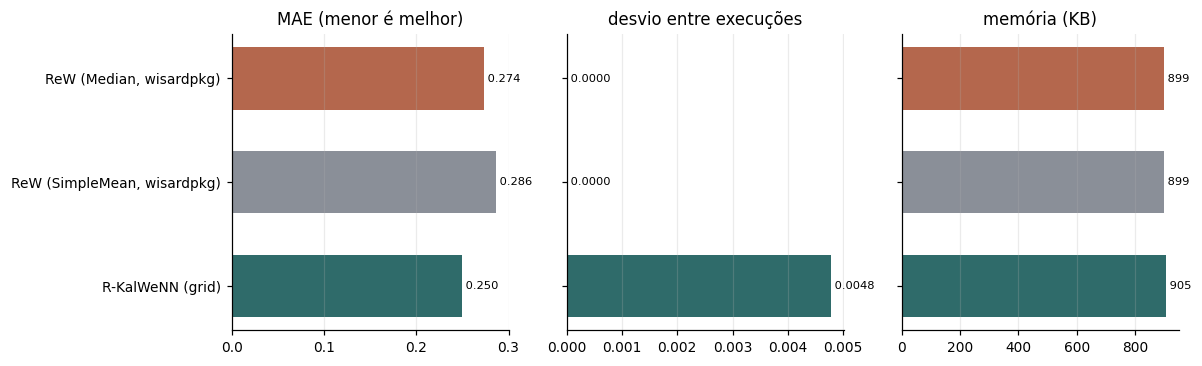

R-KalWeNN contra ReW(Median):
  MAE     : -8.7%
  desvio  : +477318284145.6%
  memória : 1.0x

A memória do R-KalWeNN é maior por construção: quatro números por célula
(c, y, p_c, p_y) contra dois da ReW (contador, soma).


In [39]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
ypos = np.arange(len(comp))[::-1]
cores = [COR_REW, COR_REF, COR_KAL]

for a, col, tit, fmt in [
    (ax[0], "MAE",        "MAE (menor é melhor)",   lambda v: f"{v:.3f}"),
    (ax[1], "MAE_dp",     "desvio entre execuções", lambda v: f"{v:.4f}"),
    (ax[2], "memoria_KB", "memória (KB)",           lambda v: f"{v:,.0f}"),
]:
    a.barh(ypos, comp[col], color=cores, height=.6)
    a.set(yticks=ypos, yticklabels=comp.modelo if a is ax[0] else [], title=tit)
    a.grid(axis="y", visible=False)
    for p_, v in zip(ypos, comp[col]):
        a.text(v, p_, " " + fmt(v), va="center", fontsize=7.5)
plt.tight_layout(); plt.show()

r_kal = comp[comp.modelo.str.startswith("R-KalWeNN")].iloc[0]
r_med = comp[comp.modelo.str.contains("Median")].iloc[0]
print("R-KalWeNN contra ReW(Median):")
print(f"  MAE     : {(r_kal.MAE/r_med.MAE - 1)*100:+.1f}%")
print(f"  desvio  : {(r_kal.MAE_dp/max(r_med.MAE_dp, 1e-12) - 1)*100:+.1f}%")
print(f"  memória : {r_kal.memoria_KB/r_med.memoria_KB:.1f}x")